#imports

In [1]:
import pandas as pd; import matplotlib.pyplot as plt; import numpy as np; from PIL import Image; import tqdm; import urllib.request; import time; from sklearn.metrics import mean_squared_error as mse

#Задача

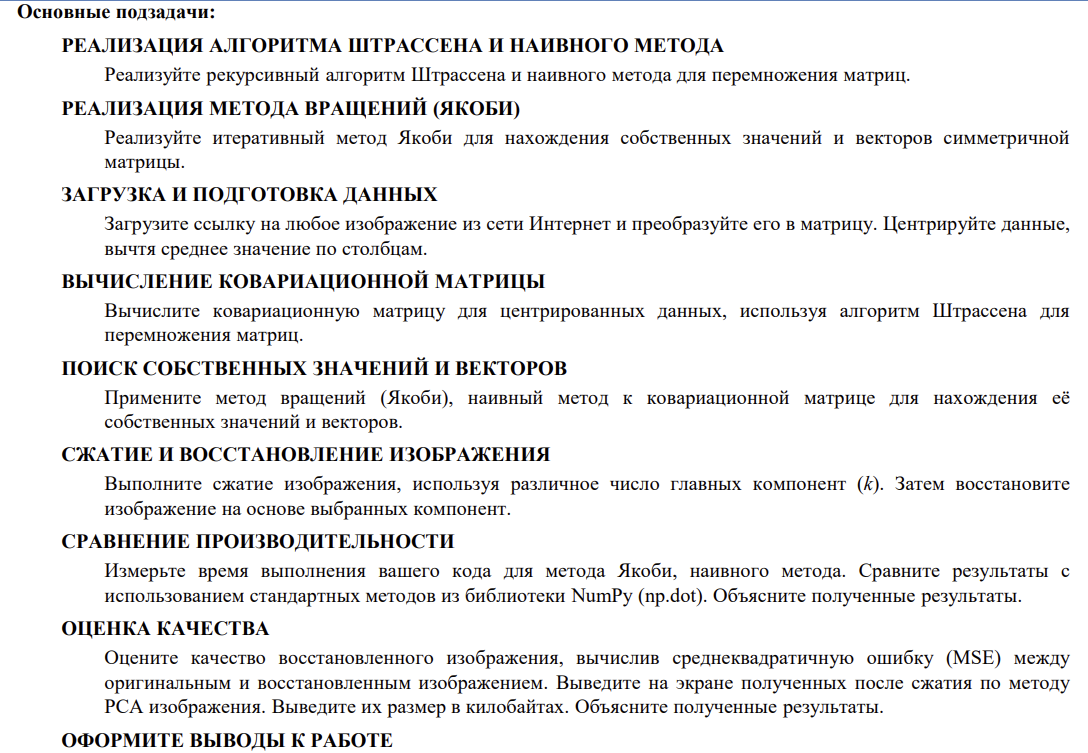

#Наивный метод

Размер исходного файла до сжатия: 312.50 KB


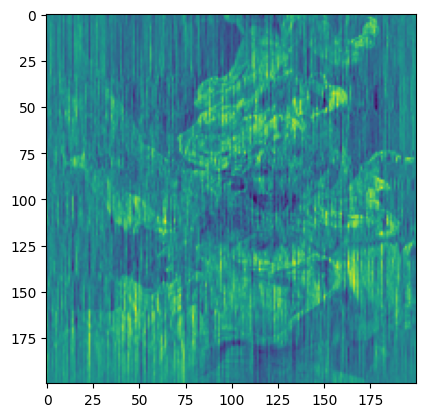

In [20]:
# Импортирование изображения
img = Image.open("/content/test.jpg").convert('L').resize((200, 200))
img_array = np.array(img, dtype=float) / 255.0
height, width = img_array.shape
original_size_kb = img_array.nbytes / 1024
print(f"Размер исходного файла до сжатия: {original_size_kb:.2f} KB")

# Нахождение ковариационной матрицы, собственных векторов
X = img_array
X_mean = np.mean(X, axis=0)
X_centered = X - X_mean
time_nostrass = time.time()
cov_matrix = (1 / (width - 1)) * (X_centered.T @ X_centered)
time_nostrass = time_nostrass - time.time()
time_nojacob = time.time()
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
time_nojacob = time_nojacob - time.time()

# Сортировка по объясняющей способности векторов, выберем n векторов
n = 100
components = np.array([i for _,i in sorted(zip(eigenvalues, eigenvectors))[::-1]][:n])

projection = X_centered @ components.T

# Восстановление изображения
X_reconstructed = projection @ components + X.mean()

image = Image.fromarray(X_reconstructed)
plt.imshow(X_reconstructed)
plt.show()

#С алгоритмом Штрассена и методом Якоби

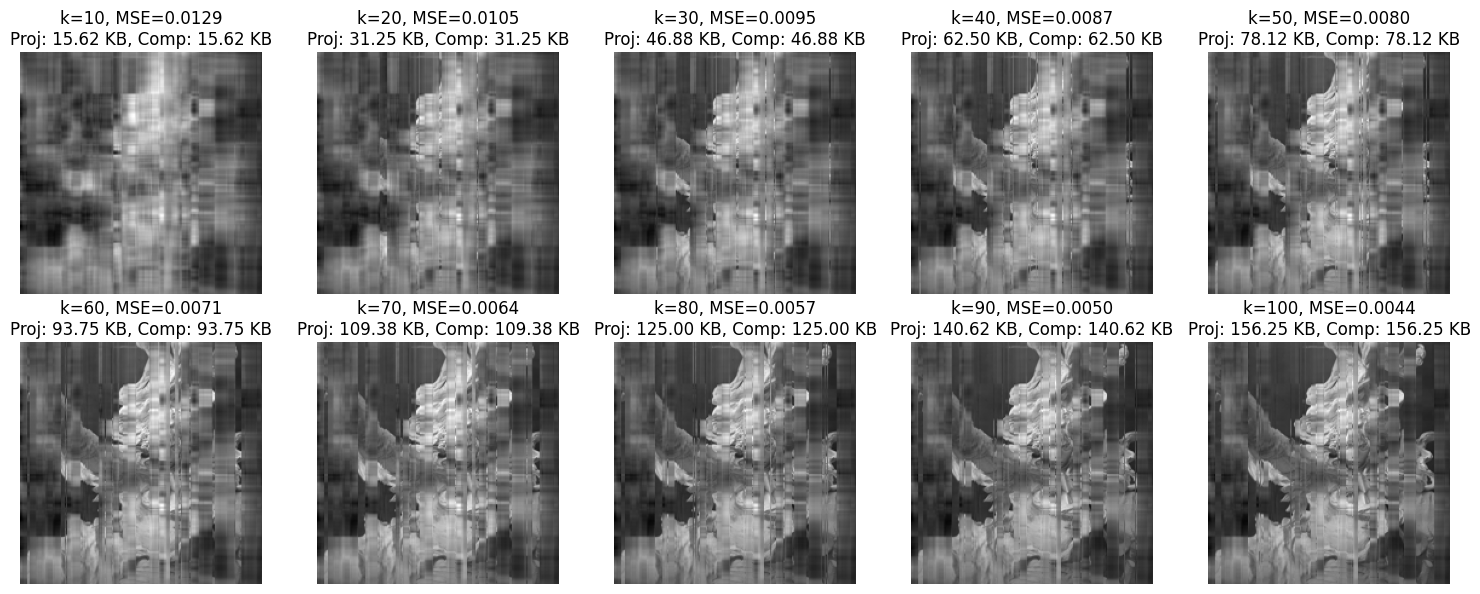

,Components,Time (s),MSE,Projection Size (KB),Components Size (KB)
0,10,0.000563,0.012877,15.625,15.625
1,20,0.000414,0.010518,31.250,31.250
2,30,0.000602,0.009451,46.875,46.875
3,40,0.000500,0.008702,62.500,62.500
4,50,0.000591,0.007985,78.125,78.125
5,60,0.000753,0.007096,93.750,93.750
6,70,0.000721,0.006431,109.375,109.375
7,80,0.000732,0.005744,125.000,125.000
8,90,0.000835,0.005014,140.625,140.625
9,100,0.000901,0.004444,156.250,156.250


In [19]:
def strassen_multiply(A, B):
    n = len(A)
    if n == 1:
        return [[A[0][0] * B[0][0]]]
    mid = n // 2
    A11, A12, A21, A22 = [row[:mid] for row in A[:mid]], [row[mid:] for row in A[:mid]], [row[:mid] for row in A[mid:]], [row[mid:] for row in A[mid:]]
    B11, B12, B21, B22 = [row[:mid] for row in B[:mid]], [row[mid:] for row in B[:mid]], [row[:mid] for row in B[mid:]], [row[mid:] for row in B[mid:]]
    P1 = strassen_multiply(A11, subtract_matrices(B12, B22))
    P2 = strassen_multiply(add_matrices(A11, A12), B22)
    P3 = strassen_multiply(add_matrices(A21, A22), B11)
    P4 = strassen_multiply(A22, subtract_matrices(B21, B11))
    P5 = strassen_multiply(add_matrices(A11, A22), add_matrices(B11, B22))
    P6 = strassen_multiply(subtract_matrices(A12, A22), add_matrices(B21, B22))
    P7 = strassen_multiply(subtract_matrices(A11, A21), add_matrices(B11, B12))
    C11 = add_matrices(subtract_matrices(add_matrices(P5, P4), P2), P6)
    C12, C21 = add_matrices(P1, P2), add_matrices(P3, P4)
    C22 = subtract_matrices(subtract_matrices(add_matrices(P5, P1), P3), P7)
    return [C11[i] + C12[i] for i in range(mid)] + [C21[i] + C22[i] for i in range(mid)]

def add_matrices(A, B):
    return [[A[i][j] + B[i][j] for j in range(len(A[0]))] for i in range(len(A))]

def subtract_matrices(A, B):
    return [[A[i][j] - B[i][j] for j in range(len(A[0]))] for i in range(len(A))]

def jacobi_eigen_iterative(matrix, max_iter=1000, epsilon=1e-10):
    n = matrix.shape[0]
    eigenvectors = np.eye(n)
    for _ in range(max_iter):
        max_val, p, q = 0, 0, 0
        for i in range(n):
            for j in range(i + 1, n):
                if abs(matrix[i, j]) > max_val:
                    max_val, p, q = abs(matrix[i, j]), i, j
        if max_val < epsilon:
            break
        theta = 0.5 * np.arctan2(2 * matrix[p, q], matrix[p, p] - matrix[q, q])
        c, s = np.cos(theta), np.sin(theta)
        rotation = np.eye(n)
        rotation[p, p], rotation[q, q] = c, c
        rotation[p, q], rotation[q, p] = -s, s
        matrix = rotation.T @ matrix @ rotation
        eigenvectors = eigenvectors @ rotation
    eigenvalues = np.diag(matrix)
    idx = eigenvalues.argsort()[::-1]
    return eigenvalues[idx], eigenvectors[:, idx]

def size_kb(array):
    return array.nbytes / 1024

# Импортирование изображения
img = Image.open("/content/test.jpg").convert('L').resize((200, 200))
img_array = np.array(img, dtype=float) / 255.0
X = img_array
X_mean = np.mean(X, axis=0)
X_centered = X - X_mean
rows, cols = X_centered.shape
X_centered_list = X_centered.tolist()

def pad_matrix(matrix):
    n, m = len(matrix), len(matrix[0])
    size = 1
    while size < max(n, m):
        size *= 2
    new_matrix = [[0] * size for _ in range(size)]
    for i in range(n):
        for j in range(m):
            new_matrix[i][j] = matrix[i][j]
    return new_matrix, n, m
# Дополним матрицу нулями для дальнейшего использования метода Штрассена.
X_padded, orig_n, orig_m = pad_matrix(X_centered_list)
X_T_padded, _, _ = pad_matrix(X_centered.T.tolist())
time_strass = time.time()
# Нахождение ковариационной матрицы, собственных векторов
cov_padded = strassen_multiply(X_padded, X_T_padded)
cov_matrix = np.array([row[:orig_m] for row in cov_padded[:orig_n]]) / (cols - 1)
time_strass = time.time() - time_strass
time_jacob = time.time()
eigenvalues, eigenvectors = jacobi_eigen_iterative(cov_matrix)
time_jacob = time.time() - time_jacob

# Выведем восстановленные изображения, их размер и отличие от исходного изображения (используя MSE)
results = []
n_values = list(range(10,110,10))
fig, axes = plt.subplots(2, len(n_values)//2, figsize=(15, 6))
axes = axes.ravel()

for i, k in enumerate(n_values):
  start_time = time.time()

  components = eigenvectors[:, :k]
  projection = X_centered @ components
  X_reconstructed = projection @ components.T + X_mean

  end_time = time.time()

  elapsed_time = end_time - start_time

  error = mse(img_array, X_reconstructed)

  projection_size = size_kb(projection)
  components_size = size_kb(components)

  results.append([k, elapsed_time, error, projection_size, components_size])

  axes[i].imshow(X_reconstructed, cmap='gray')
  axes[i].set_title(f'k={k}, MSE={error:.4f}\nProj: {projection_size:.2f} KB, Comp: {components_size:.2f} KB')
  axes[i].axis('off')

results_df = pd.DataFrame(results, columns=['Components', 'Time (s)', 'MSE', 'Projection Size (KB)', 'Components Size (KB)'])

plt.tight_layout()
plt.show()
display(results_df)

#Вывод

In [21]:
results_df['Total Size (KB)'] = results_df['Projection Size (KB)'] + results_df['Components Size (KB)']
display(results_df)
print()
print(f'Разница в секундах при подсчете ковариационной матрицы (время используя алгоритм Штрассена - время без него): \n{time_strass - time_nostrass}')
print()
print(f'Разница в секундах при нахождении собственных чисел и векторов (время используя метод вращений - время без него): \n{time_jacob  - time_nojacob}')

,Components,Time (s),MSE,Projection Size (KB),Components Size (KB),Total Size (KB)
0,10,0.000563,0.012877,15.625,15.625,31.25
1,20,0.000414,0.010518,31.250,31.250,62.50
2,30,0.000602,0.009451,46.875,46.875,93.75
3,40,0.000500,0.008702,62.500,62.500,125.00
4,50,0.000591,0.007985,78.125,78.125,156.25
5,60,0.000753,0.007096,93.750,93.750,187.50
6,70,0.000721,0.006431,109.375,109.375,218.75
7,80,0.000732,0.005744,125.000,125.000,250.00
8,90,0.000835,0.005014,140.625,140.625,281.25
9,100,0.000901,0.004444,156.250,156.250,312.50



Разница в секундах при подсчете ковариационной матрицы (время используя алгоритм Штрассена - время без него): 
34.29096269607544

Разница в секундах при нахождении собственных чисел и векторов (время используя метод вращений - время без него): 
16.808910369873047


Причина, почему с алгоритмом Штрассена и с методом якоби время больше: эти алгоритмы предназначены для работы с большими, плотными матрицами. На реализуемом примере расходы на саму реализацию алгоритма (вызовы функций, задание типов данных и другие) занимают значительную часть времени и ресурсов.

Сам алгоритм Штрассена имеет сложность меньшую наивной реализации ($O(n^{log_27}) < O(n^3)$), но в итоге проигрывает по времени из-за накладных расходов на его реализацию на практике.

Очевидно, что при добавлении количества компонент в рассмотрение, качество восстановленного изображения улучшается.

При использовании ~120 компонент мы получаем почти исходное качество со среднеквадратичной ошибкой ~0.

Сжатие при использовании PCA происходит только при количестве компонент < 100 для исходной картинки 200x200, потому что при n = 100 общий объем информации для сжатого с помощью PCA изображения равен объему информации для хранения исходного изображения (312 KB).